# From Music to Vibration: Spectrum Analysis in Python

**Goal:** learn the basic tools of Noise & Vibration (NVH) analysis (FFT, windowing, spectrogram, order analysis) by starting from something I know well, music, and then applying the same tools to a simulated run-up and to real bearing vibration measured on a test rig.

**Why:** a note is a frequency, its harmonics are multiples of it, and a resonance is a frequency where a structure vibrates strongly. Engineers analyze machines and vehicles with the same ideas, using accelerometers and microphones instead of ears.

**Honest scope:** this is a short learning project. The run-up in sections 3 and 4 is **simulated**, so it validates the method (I recover what I planted). Section 5 then applies the method to **real measured bearing data** (University of Ottawa, CC BY 4.0).

**Tools:** Python, NumPy, SciPy, matplotlib, pandas

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
Path("images").mkdir(exist_ok=True)

NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def note_to_freq(name):
    """'A4' -> 440.0 Hz (equal temperament, A4 = 440 Hz)."""
    pitch, octave = name[:-1], int(name[-1])
    midi = 12 * (octave + 1) + NOTE_NAMES.index(pitch)
    return 440.0 * 2 ** ((midi - 69) / 12)

def freq_to_note(f):
    """440.0 -> ('A4', 0.0 cents)."""
    midi = 69 + 12 * np.log2(f / 440.0)
    n = int(round(midi))
    return f"{NOTE_NAMES[n % 12]}{n // 12 - 1}", 100 * (midi - n)

## 1. A melody as a signal

The notebook builds a short demo melody in code (six notes, each with four harmonics), so there is nothing to download for this part.

In [2]:
def synth_melody(fs=22050):
    """Demo melody: notes with 4 harmonics and an exponential decay."""
    melody = [("A4", 0.5), ("C5", 0.5), ("B4", 0.5), ("A4", 0.5), ("E4", 0.5), ("A4", 1.0)]
    parts = []
    for name, dur in melody:
        t = np.arange(int(dur * fs)) / fs
        f0 = note_to_freq(name)
        tone = sum(a * np.sin(2 * np.pi * k * f0 * t) for k, a in enumerate([1.0, 0.5, 0.3, 0.15], start=1))
        envelope = np.minimum(t / 0.01, 1) * np.exp(-3 * t)
        parts.append(tone * envelope)
    x = np.concatenate(parts)
    return fs, x / np.abs(x).max()

fs, x = synth_melody()
t = np.arange(len(x)) / fs
print(f"Source: demo melody | sampling rate: {fs} Hz | duration: {len(x) / fs:.1f} s")

Source: demo melody | sampling rate: 22050 Hz | duration: 3.5 s


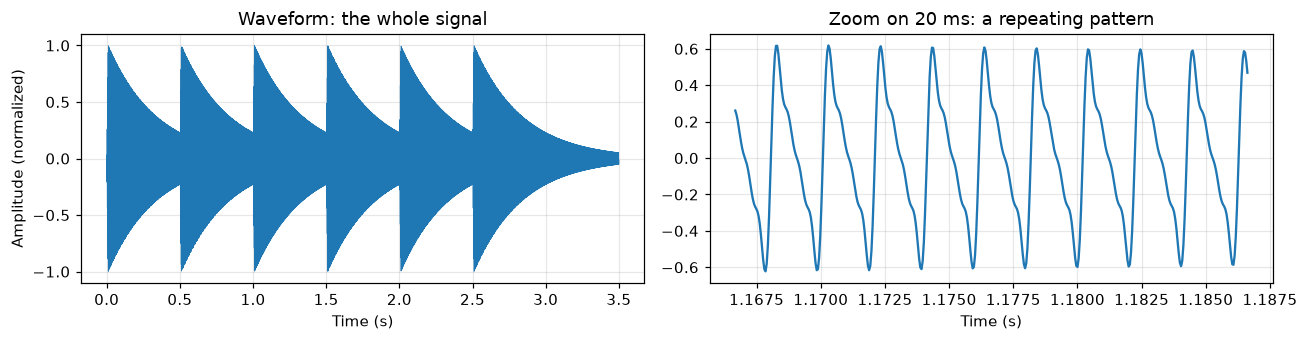

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(t, x, lw=0.5)
axes[0].set(title="Waveform: the whole signal", xlabel="Time (s)", ylabel="Amplitude (normalized)")
mid = len(x) // 3
axes[1].plot(t[mid:mid + int(0.02 * fs)], x[mid:mid + int(0.02 * fs)])
axes[1].set(title="Zoom on 20 ms: a repeating pattern", xlabel="Time (s)")
plt.tight_layout()
plt.savefig("images/01_waveform.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** in the time domain I can see when notes start and how loud they are, but not *which* notes are playing. The zoom shows a periodic shape; how often it repeats is the pitch. The FFT makes this visible directly.

## 2. FFT: from time to frequency

The FFT splits a signal into its frequency components. I use a **Hann window** to reduce spectral leakage, then find the peaks and name the notes.

In [4]:
def spectrum(sig, fs, window="hann"):
    """Single-sided amplitude spectrum with the chosen window."""
    w = signal.get_window(window, len(sig))
    X = np.fft.rfft(sig * w)
    f = np.fft.rfftfreq(len(sig), 1 / fs)
    return f, np.abs(X) / np.sum(w) * 2

f, mag = spectrum(x, fs)
df = f[1] - f[0]
peaks, _ = signal.find_peaks(mag, height=0.05 * mag.max(), distance=max(1, int(20 / df)))
peaks = peaks[(f[peaks] > 60) & (f[peaks] < 3000)]

rows = []
for p in peaks:
    note, cents = freq_to_note(f[p])
    rows.append({"frequency_Hz": round(f[p], 1), "relative_level": round(mag[p] / mag[peaks].max(), 2),
                 "nearest_note": note, "offset_cents": round(cents)})
notes_table = pd.DataFrame(rows).sort_values("relative_level", ascending=False).reset_index(drop=True)
notes_table.head(10)

,frequency_Hz,relative_level,nearest_note,offset_cents
0,440.0,1.00,A4,0
1,329.7,0.56,E4,0
2,493.7,0.50,B4,-1
3,880.0,0.50,A5,0
4,988.3,0.37,B5,1
5,1320.0,0.31,E6,2
6,659.1,0.28,E5,0
7,523.1,0.24,C5,0
8,1481.7,0.15,F#6,2
9,1760.0,0.15,A6,0


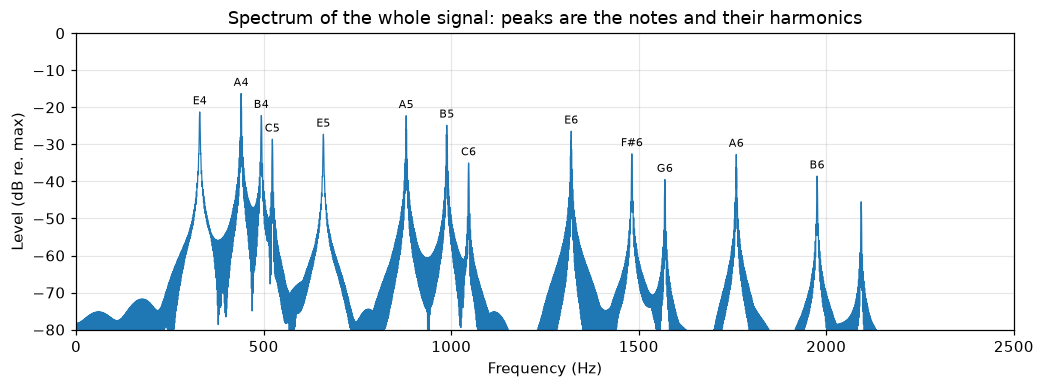

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(f, 20 * np.log10(mag + 1e-12), lw=0.8)
for p in peaks:
    ax.annotate(freq_to_note(f[p])[0], (f[p], 20 * np.log10(mag[p])), textcoords="offset points",
                xytext=(0, 5), ha="center", fontsize=7)
ax.set(xlim=(0, 2500), ylim=(-80, 0), xlabel="Frequency (Hz)", ylabel="Level (dB re. max)",
       title="Spectrum of the whole signal: peaks are the notes and their harmonics")
plt.savefig("images/02_spectrum_notes.png", dpi=150, bbox_inches="tight")
plt.show()

### Why the window matters

A signal chopped out of a longer recording has abrupt edges. With no window (rectangular) the FFT leaks energy into neighboring frequencies; a Hann window trades a slightly wider peak for much lower leakage.

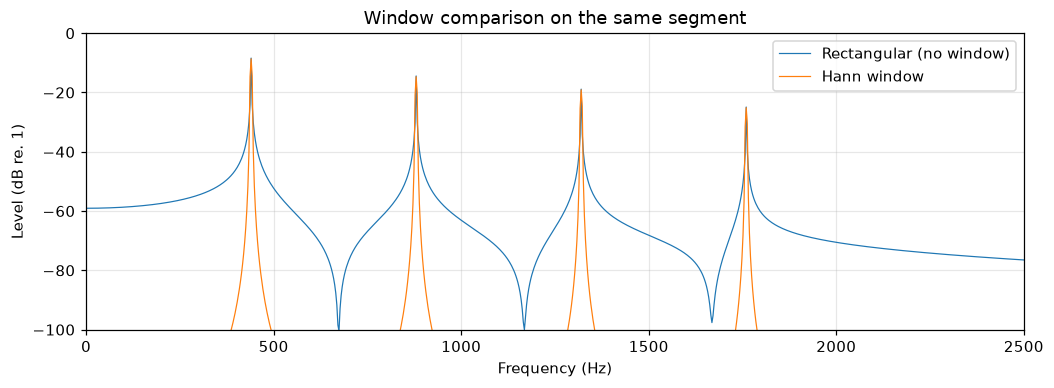

Median level above 1.5 kHz: rectangular -88 dB, Hann -218 dB


In [6]:
seg = x[int(0.05 * fs): int(0.40 * fs)]          # part of the first note
f_r, m_r = spectrum(seg, fs, "boxcar")
f_h, m_h = spectrum(seg, fs, "hann")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(f_r, 20 * np.log10(m_r + 1e-12), lw=0.8, label="Rectangular (no window)")
ax.plot(f_h, 20 * np.log10(m_h + 1e-12), lw=0.8, label="Hann window")
ax.set(xlim=(0, 2500), ylim=(-100, 0), xlabel="Frequency (Hz)", ylabel="Level (dB re. 1)",
       title="Window comparison on the same segment")
ax.legend()
plt.savefig("images/03_window_leakage.png", dpi=150, bbox_inches="tight")
plt.show()

floor_r = np.median(20 * np.log10(m_r[f_r > 1500] + 1e-12))
floor_h = np.median(20 * np.log10(m_h[f_h > 1500] + 1e-12))
print(f"Median level above 1.5 kHz: rectangular {floor_r:.0f} dB, Hann {floor_h:.0f} dB")

## 3. Spectrogram: frequency over time

A spectrogram shows *when* each frequency is present. For music it shows the melody; for a machine it shows how vibration changes with speed.

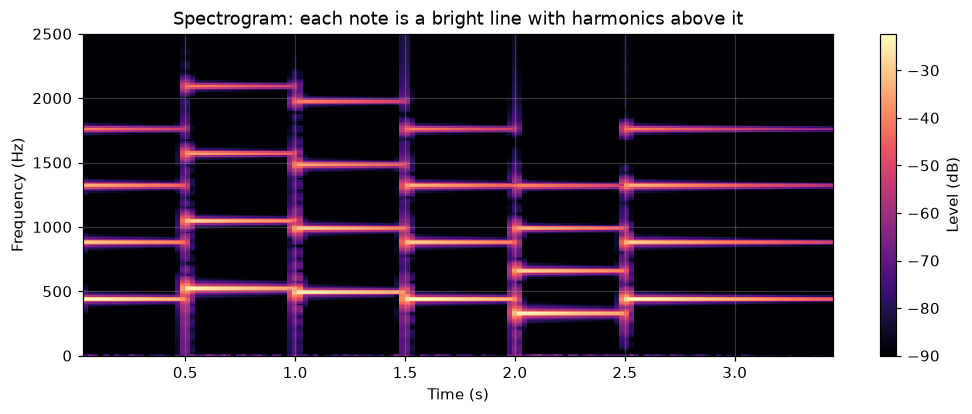

In [7]:
f_s, t_s, Sxx = signal.spectrogram(x, fs, window="hann", nperseg=2048, noverlap=1536, mode="magnitude")

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.pcolormesh(t_s, f_s, 20 * np.log10(Sxx + 1e-9), shading="auto", vmin=-90, cmap="magma")
ax.set(ylim=(0, 2500), xlabel="Time (s)", ylabel="Frequency (Hz)",
       title="Spectrogram: each note is a bright line with harmonics above it")
fig.colorbar(im, ax=ax, label="Level (dB)")
plt.savefig("images/04_music_spectrogram.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. The same tools on machine vibration (simulated)

I simulate an accelerometer signal from a machine whose rotation speed ramps up from 1,000 to 3,000 rpm over 20 s (a *run-up*, a standard NVH test). Vibration appears at the **orders** of the rotation frequency (1x, 2x, 3x), and the structure has a **resonance at 90 Hz** that amplifies whatever passes through it.

- Rotation frequency: `rpm / 60` Hz.
- Order *k* vibration: frequency `k * rpm / 60` Hz.
- A resonance is excited when an order crosses 90 Hz: order 2 at 2,700 rpm and order 3 at 1,800 rpm. Order 1 would need 5,400 rpm, outside the test range.

If the analysis is right, it should recover these two speeds from the signal alone.

In [8]:
FS_V = 2000                      # accelerometer sampling rate (Hz)
F_RES, ZETA = 90.0, 0.05         # structural resonance (Hz) and damping ratio
ORDERS = {1: 1.0, 2: 0.6, 3: 0.4}  # relative strength of each order

def resonance_gain(freq):
    """Magnitude of a single-degree-of-freedom resonance."""
    r = freq / F_RES
    return 1 / np.sqrt((1 - r**2) ** 2 + (2 * ZETA * r) ** 2)

def simulate_vibration(rpm, fs=FS_V, noise=0.05, seed=0):
    """Vibration signal for a given rpm profile (one value per sample)."""
    f_rot = rpm / 60.0
    phase = 2 * np.pi * np.cumsum(f_rot) / fs
    sig = sum(a * resonance_gain(k * f_rot) * np.sin(k * phase) for k, a in ORDERS.items())
    return sig + noise * np.random.default_rng(seed).standard_normal(len(rpm))

T = 20
t_v = np.arange(0, T, 1 / FS_V)
rpm_v = np.linspace(1000, 3000, t_v.size)
vib = simulate_vibration(rpm_v)
print(f"{len(vib)} samples, {T} s at {FS_V} Hz")

40000 samples, 20 s at 2000 Hz


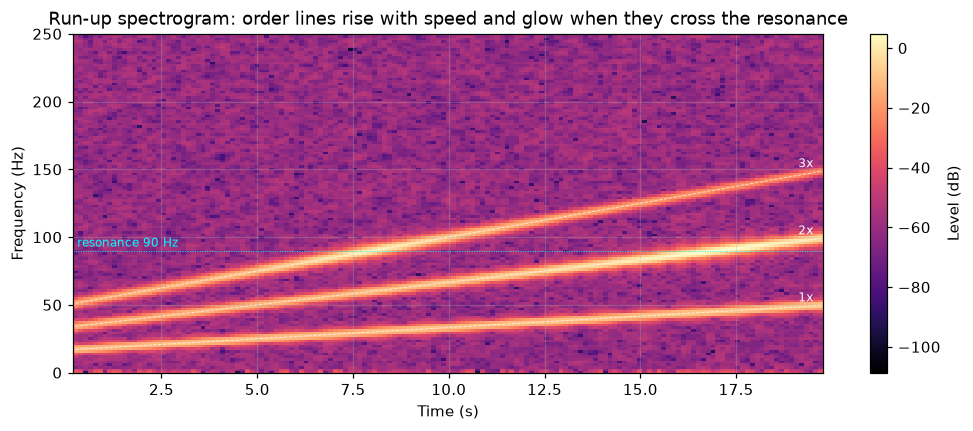

In [9]:
f_v, t_sv, S_v = signal.spectrogram(vib, FS_V, window="hann", nperseg=1024, noverlap=768, mode="magnitude")
rpm_at = np.interp(t_sv, t_v, rpm_v)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.pcolormesh(t_sv, f_v, 20 * np.log10(S_v + 1e-6), shading="auto", cmap="magma")
for k in ORDERS:
    ax.plot(t_sv, k * rpm_at / 60, "w--", lw=0.6, alpha=0.7)
    ax.text(t_sv[-1] * 0.99, k * rpm_at[-1] / 60 + 3, f"{k}x", color="w", ha="right", fontsize=8)
ax.axhline(F_RES, color="cyan", lw=0.6, ls=":")
ax.text(0.3, F_RES + 3, "resonance 90 Hz", color="cyan", fontsize=8)
ax.set(ylim=(0, 250), xlabel="Time (s)", ylabel="Frequency (Hz)",
       title="Run-up spectrogram: order lines rise with speed and glow when they cross the resonance")
fig.colorbar(im, ax=ax, label="Level (dB)")
plt.savefig("images/05_vibration_runup.png", dpi=150, bbox_inches="tight")
plt.show()

### Order cuts: amplitude of each order versus speed

To check the analysis, I follow each order through the spectrogram (taking the amplitude at `k * rpm / 60` Hz for every time slice) and look for the speed where it peaks.

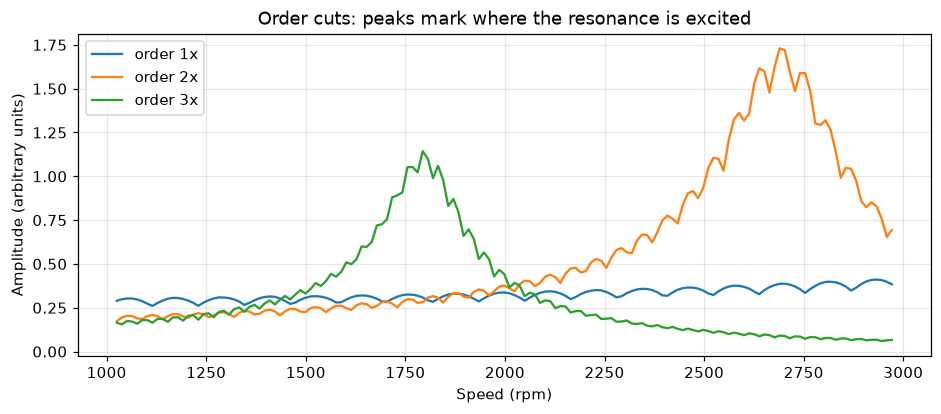

,order,peak_found_rpm,expected_rpm,error_rpm
0,2x,2690,2700,-10
1,3x,1794,1800,-6


In [10]:
order_cuts = {}
for k in ORDERS:
    amp = [S_v[np.argmin(np.abs(f_v - k * r / 60)), i] for i, r in enumerate(rpm_at)]
    order_cuts[k] = np.array(amp)

fig, ax = plt.subplots(figsize=(10, 3.8))
for k, amp in order_cuts.items():
    ax.plot(rpm_at, amp, label=f"order {k}x")
ax.set(xlabel="Speed (rpm)", ylabel="Amplitude (arbitrary units)",
       title="Order cuts: peaks mark where the resonance is excited")
ax.legend()
plt.savefig("images/06_order_cuts.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for k in (2, 3):
    found = rpm_at[np.argmax(order_cuts[k])]
    expected = 60 * F_RES / k
    rows.append({"order": f"{k}x", "peak_found_rpm": round(found), "expected_rpm": round(expected),
                 "error_rpm": round(found - expected)})
pd.DataFrame(rows)

### Steady-state spectrum (PSD)

At a constant speed, a power spectral density (Welch method) shows the orders as sharp peaks. Here the machine runs at 2,400 rpm (40 Hz rotation).

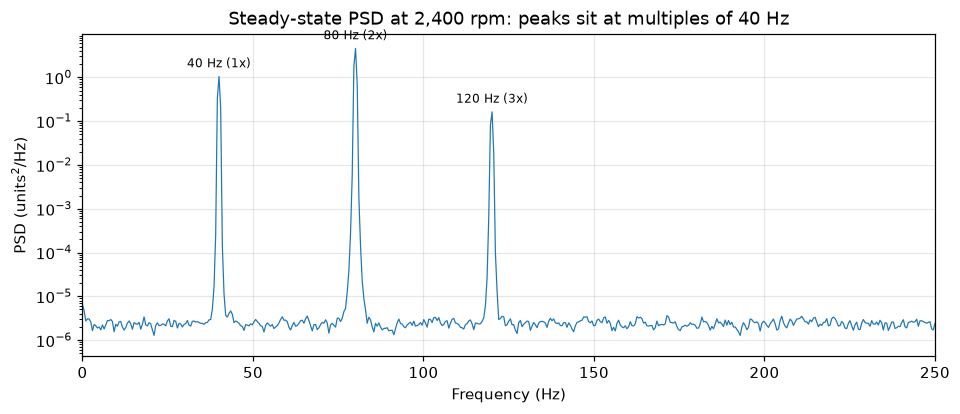

Peaks (Hz): [ 40.   80.1 120.1]


In [11]:
rpm_const = np.full(int(30 * FS_V), 2400.0)
vib_const = simulate_vibration(rpm_const, seed=1)
f_p, psd = signal.welch(vib_const, FS_V, window="hann", nperseg=4096)

pk, _ = signal.find_peaks(psd, height=psd.max() * 1e-3, distance=int(10 / (f_p[1] - f_p[0])))
pk = pk[f_p[pk] < 250]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.semilogy(f_p, psd, lw=0.8)
for p in pk:
    ax.annotate(f"{f_p[p]:.0f} Hz ({f_p[p] / 40:.0f}x)", (f_p[p], psd[p]), textcoords="offset points",
                xytext=(0, 6), ha="center", fontsize=8)
ax.set(xlim=(0, 250), xlabel="Frequency (Hz)", ylabel="PSD (units$^2$/Hz)",
       title="Steady-state PSD at 2,400 rpm: peaks sit at multiples of 40 Hz")
plt.savefig("images/07_steady_psd.png", dpi=150, bbox_inches="tight")
plt.show()
print("Peaks (Hz):", np.round(f_p[pk], 1))

## 5. Real machine data: bearing vibration under changing speed

Dataset: Huang & Baddour, *Bearing Vibration Data under Time-varying Rotational Speed Conditions*, Mendeley Data, DOI 10.17632/v43hmbwxpm.2 (CC BY 4.0). An accelerometer (`Channel_1`) and a shaft encoder (`Channel_2`, 1,024 pulses per revolution) were recorded at 200 kHz for 10 s while the speed increased. I use one **healthy** file (`H-A-1.mat`) and one with an **inner-race defect** (`I-A-2.mat`), placed in `data/`.

Method: (1) get the speed from the encoder pulses, (2) resample the vibration envelope from time to shaft angle, so a fault that repeats once per ball pass lines up at a fixed **order** even though the speed changes, (3) compare the order spectra.

In [12]:
FS_R, PPR = 200_000, 1024
REAL = {"healthy": Path("data/H-A-1.mat"), "inner-race defect": Path("data/I-A-2.mat")}

def load_real(path):
    from scipy.io import loadmat
    m = loadmat(path)
    return m["Channel_1"].ravel(), m["Channel_2"].ravel()

def speed_profile(enc, win=0.1):
    """Shaft speed (rpm) from the encoder: revolutions completed per 0.1 s window."""
    t_p = pulse_times(enc)
    rev = np.arange(len(t_p)) / PPR
    grid = np.arange(t_p[0], t_p[-1], win)
    return grid[1:], np.diff(np.interp(grid, t_p, rev)) / win * 60

def pulse_times(enc):
    """Time of each rising edge of the encoder signal (sub-sample interpolation)."""
    thr = (enc.max() + enc.min()) / 2
    i = np.flatnonzero((enc[:-1] < thr) & (enc[1:] >= thr))
    return (i + (thr - enc[i]) / (enc[i + 1] - enc[i])) / FS_R

if not all(p.exists() for p in REAL.values()):
    print("Real-data files not found in data/. Download them from the dataset page (see README) to run this section.")
    real = {}
else:
    real = {name: load_real(p) for name, p in REAL.items()}
    for name, (x_r, e_r) in real.items():
        _, rpm = speed_profile(e_r)
        print(f"{name}: speed from {rpm[:3].mean():.0f} rpm to {rpm[-3:].mean():.0f} rpm")

healthy: speed from 864 rpm to 1418 rpm
inner-race defect: speed from 788 rpm to 1525 rpm


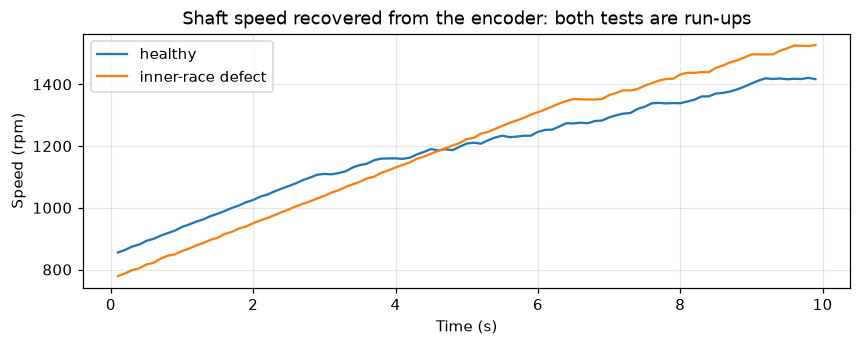

In [13]:
fig, ax = plt.subplots(figsize=(9, 3))
for name, (x_r, e_r) in real.items():
    t_s, rpm = speed_profile(e_r)
    ax.plot(t_s, rpm, label=name)
ax.set(xlabel="Time (s)", ylabel="Speed (rpm)", title="Shaft speed recovered from the encoder: both tests are run-ups")
ax.legend()
plt.savefig("images/08_real_speed.png", dpi=150, bbox_inches="tight")
plt.show()

Expected fault orders: inner race 5.43x, outer race 3.57x


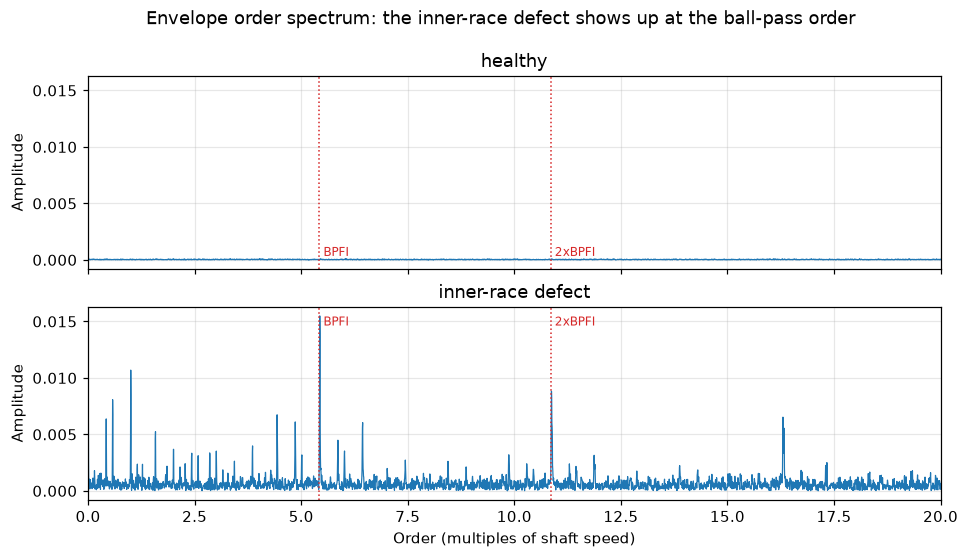

,test,strongest_order,amplitude,second_order
0,healthy,6.04,0.00012,4.03
1,inner-race defect,5.44,0.01549,10.87


In [14]:
def order_spectrum(x_r, e_r, band=(5000, 20000), samples_per_rev=64):
    """Envelope order spectrum: band-pass, envelope, resample to angle, FFT."""
    t_p = pulse_times(e_r)
    rev = np.arange(len(t_p)) / PPR
    sos = signal.butter(4, band, "bp", fs=FS_R, output="sos")
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x_r)))
    env -= env.mean()
    t = np.arange(len(x_r)) / FS_R
    ok = (t >= t_p[0]) & (t <= t_p[-1])
    rev_at_sample = np.interp(t[ok], t_p, rev)
    grid = np.arange(rev_at_sample[0], rev_at_sample[-1], 1 / samples_per_rev)
    env_a = np.interp(grid, rev_at_sample, env[ok])
    w = signal.get_window("hann", len(env_a))
    X = np.abs(np.fft.rfft(env_a * w)) / w.sum() * 2
    return np.fft.rfftfreq(len(env_a), 1 / samples_per_rev), X

# Expected inner-race fault order from the bearing geometry (assumed ER-16K: 9 balls, d = 7.94 mm, D = 38.52 mm)
N_BALLS, D_BALL, D_PITCH = 9, 7.94, 38.52
BPFI = N_BALLS / 2 * (1 + D_BALL / D_PITCH)
BPFO = N_BALLS / 2 * (1 - D_BALL / D_PITCH)
print(f"Expected fault orders: inner race {BPFI:.2f}x, outer race {BPFO:.2f}x")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
summary = []
for ax, (name, (x_r, e_r)) in zip(axes, real.items()):
    o, X = order_spectrum(x_r, e_r)
    m = (o > 1.5) & (o < 20)
    pk, _ = signal.find_peaks(X * m, distance=15)
    top = pk[np.argsort(X[pk])[::-1][:3]]
    summary.append({"test": name, "strongest_order": round(o[top[0]], 2), "amplitude": round(X[top[0]], 5),
                    "second_order": round(o[top[1]], 2)})
    ax.plot(o, X, lw=0.8)
    for k, lab in [(BPFI, "BPFI"), (2 * BPFI, "2xBPFI")]:
        ax.axvline(k, color="C3", ls=":", lw=1)
        ax.text(k, ax.get_ylim()[1] * 0.9, f" {lab}", color="C3", fontsize=8)
    ax.set(xlim=(0, 20), ylabel="Amplitude", title=name)
axes[-1].set_xlabel("Order (multiples of shaft speed)")
fig.suptitle("Envelope order spectrum: the inner-race defect shows up at the ball-pass order", y=1.0)
plt.savefig("images/09_real_order_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(summary)

## 6. Findings

- **Notes are peaks.** The FFT recovers the melody's pitches (A4 440.0 Hz, B4, C5, E4) and their harmonics, each within about 2 cents of the equal-tempered value.
- **The window matters.** On the same segment, a Hann window lowers the spectral leakage far from the peaks to about -218 dB, against about -88 dB for the rectangular window (median level above 1.5 kHz).
- **Orders rise with speed.** In the run-up spectrogram the 1x, 2x and 3x lines climb with rpm, at k x rpm/60 Hz.
- **Resonance shows up as a peak in an order cut.** The 2x order peaks at about 2,690 rpm (planted: 2,700) and the 3x order at about 1,794 rpm (planted: 1,800), both where the order frequency crosses the 90 Hz resonance.
- **Real data confirms it.** On measured bearing vibration (inner-race defect, speed rising from about 790 to 1,525 rpm), the envelope order spectrum has its strongest peak at order 5.44, next to the expected inner-race order of 5.43, with a harmonic at 10.87. Its amplitude is about 130 times the largest peak of the healthy bearing (0.0155 versus 0.00012), which shows no ball-pass peak.
- **Steady state confirms the orders.** At 2,400 rpm the PSD peaks at 40.0, 80.1 and 120.1 Hz, which are 1x, 2x and 3x.

## 7. Limitations and next steps

- **The vibration data is simulated.** I planted the resonance (90 Hz, 5% damping) and the orders myself, so this project validates the method (it recovers what was planted); it is not a finding about a real machine.
- **The resonance model is a single degree of freedom.** Real structures have many modes, and the damping would be estimated, not known.
- **Next steps:** also test the outer-race and ball defects, estimate damping from the peak width (half-power method), and add a measured resonance from a structure.